# Projet Data Mining — Prévision des Ventes Mensuelles
### Store Sales Time Series Forecasting — Kaggle
 
**Modèles :** ARIMA · Prophet · LSTR  
**Données :** 2,974,158 observations · 54 magasins · 33 familles · 2013–2017

## 1.  Installation & Importation

In [1]:
!pip install pandas numpy prophet statsmodels scikit-learn matplotlib seaborn scipy  --quiet



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from itertools import product
from scipy.optimize import minimize
from scipy.special import expit

plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
sns.set_palette("husl")
print(" Librairies importées")


Importing plotly failed. Interactive plots will not work.


 Librairies importées


## 2.  Chargement des Données

In [65]:
# Chargement de tous les fichiers
train        = pd.read_csv('data/train.csv',           parse_dates=['date'])
test         = pd.read_csv('data/test.csv',            parse_dates=['date'])
stores       = pd.read_csv('data/stores.csv')
oil          = pd.read_csv('data/oil.csv',             parse_dates=['date'])
holidays     = pd.read_csv('data/holidays_events.csv', parse_dates=['date'])
transactions = pd.read_csv('data/transactions.csv',    parse_dates=['date'])

# Garder uniquement les mois complets 
train = train[train['date'] < '2017-08-01']

# Colonnes utiles pour la modélisation
train['year']  = train['date'].dt.year
train['month'] = train['date'].dt.month

print("=== DIMENSIONS ===")
for name, df in [('train', train), ('test', test), ('stores', stores),
                  ('oil', oil), ('holidays', holidays), ('transactions', transactions)]:
    print(f"  {name:15s}: {df.shape[0]:>10,} lignes × {df.shape[1]} colonnes")




=== DIMENSIONS ===
  train          :  2,974,158 lignes × 8 colonnes
  test           :     28,512 lignes × 5 colonnes
  stores         :         54 lignes × 5 colonnes
  oil            :      1,218 lignes × 2 colonnes
  holidays       :        350 lignes × 6 colonnes
  transactions   :     83,488 lignes × 3 colonnes


In [36]:
# Aperçu des fichiers principaux
for name, df in [('train', train), ('stores', stores), ('oil', oil),
                  ('holidays', holidays), ('transactions', transactions)]:
    print(f"\n=== {name}.csv ===")
    display(df.head(3))



=== train.csv ===


,id,date,store_nbr,family,sales,onpromotion,year,month
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,2013,1
1,1,2013-01-01,1,BABY CARE,0.0,0,2013,1
2,2,2013-01-01,1,BEAUTY,0.0,0,2013,1



=== stores.csv ===


,store_nbr,city,state,type,cluster
0,1,Quito,Pichincha,D,13
1,2,Quito,Pichincha,D,13
2,3,Quito,Pichincha,D,8



=== oil.csv ===


,date,dcoilwtico
0,2013-01-01,NaN
1,2013-01-02,93.14
2,2013-01-03,92.97



=== holidays.csv ===


,date,type,locale,locale_name,description,transferred
0,2012-03-02,Holiday,Local,Manta,Fundacion de Manta,False
1,2012-04-01,Holiday,Regional,Cotopaxi,Provincializacion de Cotopaxi,False
2,2012-04-12,Holiday,Local,Cuenca,Fundacion de Cuenca,False



=== transactions.csv ===


,date,store_nbr,transactions
0,2013-01-01,25,770
1,2013-01-02,1,2111
2,2013-01-02,2,2358


## 3.  Analyse Exploratoire (EDA)
### 3.1 Statistiques Descriptives

In [37]:
# Stats descriptives de tous les fichiers
for name, df, cols in [
    ('TRAIN  — sales & onpromotion', train,        ['sales','onpromotion']),
    ('OIL    — dcoilwtico',          oil,           ['dcoilwtico']),
    ('TRANSACTIONS',                 transactions,  ['transactions']),
]:
    print(f"\n{'='*50}")
    print(name)
    print('='*50)
    display(df[cols].describe().round(2))

print(f"\n{'='*50}")
print("STORES — types & clusters")
print('='*50)
display(stores['type'].value_counts().to_frame('count'))

print(f"\n{'='*50}")
print("HOLIDAYS — types & locales")
print('='*50)
display(holidays['type'].value_counts().to_frame('count'))
display(holidays['locale'].value_counts().to_frame('count'))
print(f"Fériés transférés : {holidays['transferred'].sum()} / {len(holidays)}")

# ============================================================
# STATISTIQUES DESCRIPTIVES — TOUS LES FICHIERS
# ============================================================

print("=" * 60)
print("1. TRAIN — sales & onpromotion")
print("=" * 60)
display(train[['sales', 'onpromotion']].describe().round(2))
print(f"\n% de zéros (sales=0) : {(train['sales']==0).mean()*100:.1f}%")
print(f"Nb magasins uniques   : {train['store_nbr'].nunique()}")
print(f"Nb familles uniques   : {train['family'].nunique()}")

print("\n" + "=" * 60)
print("2. OIL — prix du pétrole WTI")
print("=" * 60)
display(oil[['dcoilwtico']].describe().round(2))
print(f"Valeurs manquantes : {oil['dcoilwtico'].isnull().sum()}")

print("\n" + "=" * 60)
print("3. TRANSACTIONS")
print("=" * 60)
display(transactions[['transactions']].describe().round(2))
print(f"Nb jours couverts  : {transactions['date'].nunique()}")

print("\n" + "=" * 60)
print("4. HOLIDAYS — types et locales")
print("=" * 60)
print("\nRépartition par type :")
display(holidays['type'].value_counts().to_frame('count'))
print("\nRépartition par locale :")
display(holidays['locale'].value_counts().to_frame('count'))
print(f"\nFériés transférés : {holidays['transferred'].sum()} / {len(holidays)}")

print("\n" + "=" * 60)
print("5. CORRÉLATIONS — Variables externes vs Ventes")
print("=" * 60)

# Préparer séries mensuelles pour corrélations
sales_m = train.groupby(pd.Grouper(key='date', freq='ME'))['sales'].sum().reset_index()
sales_m.columns = ['date', 'sales']

oil_m = oil.set_index('date')['dcoilwtico'].resample('ME').mean().reset_index()
trans_m = transactions.groupby(pd.Grouper(key='date', freq='ME'))['transactions'].sum().reset_index()
promo_m = train.groupby(pd.Grouper(key='date', freq='ME'))['onpromotion'].sum().reset_index()

merged_corr = sales_m.merge(oil_m, on='date', how='left')
merged_corr = merged_corr.merge(trans_m, on='date', how='left')
merged_corr = merged_corr.merge(promo_m, on='date', how='left')

corr_matrix = merged_corr[['sales','dcoilwtico','transactions','onpromotion']].corr()
display(corr_matrix.round(3))

print(f"\nCorrélation Ventes / Pétrole       : {merged_corr['sales'].corr(merged_corr['dcoilwtico']):.3f}")
print(f"Corrélation Ventes / Transactions  : {merged_corr['sales'].corr(merged_corr['transactions']):.3f}")
print(f"Corrélation Ventes / Promotions    : {merged_corr['sales'].corr(merged_corr['onpromotion']):.3f}")



TRAIN  — sales & onpromotion


,sales,onpromotion
count,2974158.00,2974158.00
mean,356.81,2.57
std,1100.59,12.17
min,0.00,0.00
25%,0.00,0.00
50%,11.00,0.00
75%,195.00,0.00
max,124717.00,741.00



OIL    — dcoilwtico


,dcoilwtico
count,1175.00
mean,67.71
std,25.63
min,26.19
25%,46.40
50%,53.19
75%,95.66
max,110.62



TRANSACTIONS


...


Répartition par locale :


,count
locale,
National,174
Local,152
Regional,24



Fériés transférés : 12 / 350

5. CORRÉLATIONS — Variables externes vs Ventes


,sales,dcoilwtico,transactions,onpromotion
sales,1.000,-0.780,0.640,0.823
dcoilwtico,-0.780,1.000,-0.435,-0.682
transactions,0.640,-0.435,1.000,0.476
onpromotion,0.823,-0.682,0.476,1.000



Corrélation Ventes / Pétrole       : -0.780
Corrélation Ventes / Transactions  : 0.640
Corrélation Ventes / Promotions    : 0.823


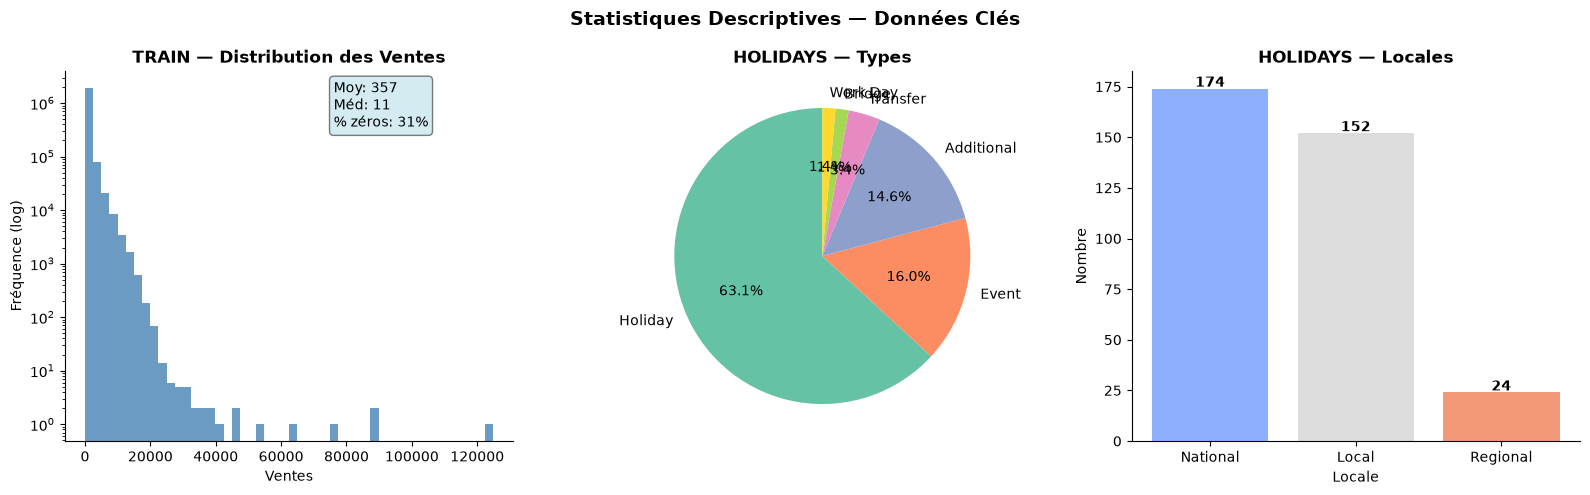

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. TRAIN — Distribution des ventes
axes[0].hist(train[train['sales']>0]['sales'], bins=50, color='steelblue', alpha=0.8)
axes[0].set_yscale('log')
axes[0].set_title('TRAIN — Distribution des Ventes', fontweight='bold')
axes[0].set_xlabel('Ventes')
axes[0].set_ylabel('Fréquence (log)')
axes[0].text(0.6, 0.85,
    f"Moy: {train['sales'].mean():.0f}\nMéd: {train['sales'].median():.0f}\n% zéros: {(train['sales']==0).mean()*100:.0f}%",
    transform=axes[0].transAxes, fontsize=10,
    bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.5))

# 2. HOLIDAYS — Répartition par type
hol_type = holidays['type'].value_counts()
colors_hol = sns.color_palette("Set2", len(hol_type))
axes[1].pie(hol_type.values, labels=hol_type.index,
            autopct='%1.1f%%', colors=colors_hol, startangle=90)
axes[1].set_title('HOLIDAYS — Types', fontweight='bold')

# 3. HOLIDAYS — Répartition par locale
hol_locale = holidays['locale'].value_counts()
bars = axes[2].bar(hol_locale.index, hol_locale.values,
                   color=sns.color_palette("coolwarm", len(hol_locale)))
axes[2].set_title('HOLIDAYS — Locales', fontweight='bold')
axes[2].set_xlabel('Locale')
axes[2].set_ylabel('Nombre')
for i, (idx, val) in enumerate(hol_locale.items()):
    axes[2].text(i, val + 1, str(val), ha='center', fontweight='bold')

plt.suptitle('Statistiques Descriptives — Données Clés', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('plot_all_stats.png', dpi=150, bbox_inches='tight')
plt.show()

### 3.2 Familles — Analyse des zéros

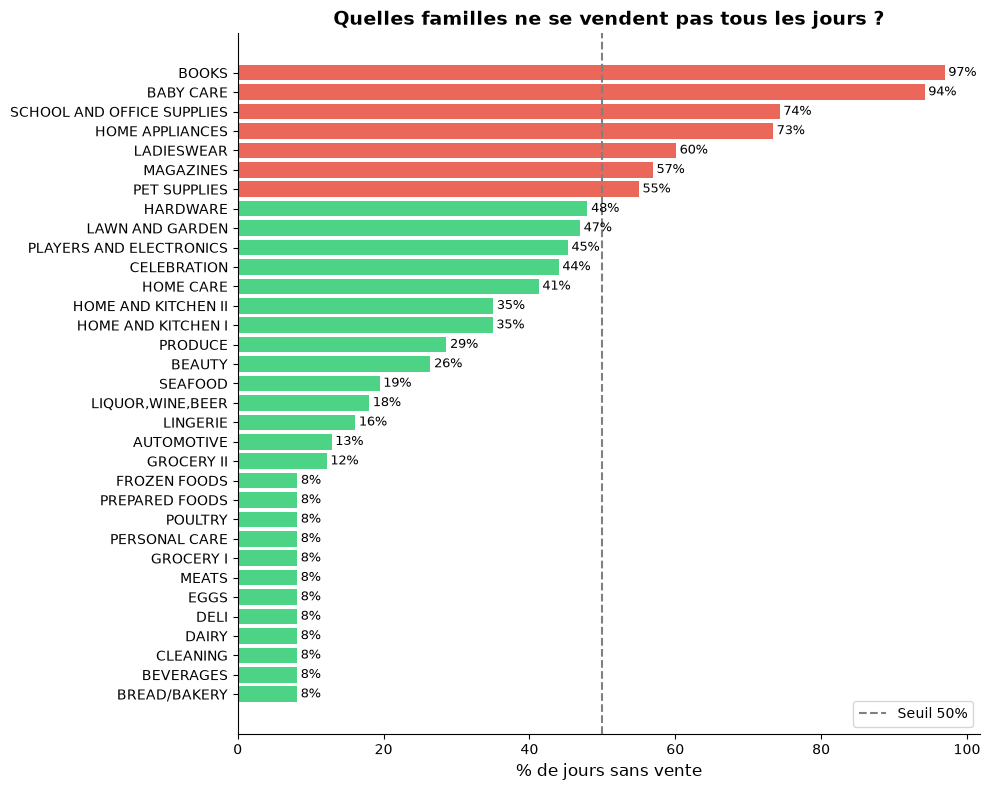

In [39]:
# % de jours sans vente par famille
zero_pct = (train[train['sales']==0].groupby('family').size() /
            train.groupby('family').size() * 100).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 8))
colors = ['#e74c3c' if v > 50 else '#2ecc71' for v in zero_pct.values]
bars = ax.barh(zero_pct.index, zero_pct.values, color=colors, alpha=0.85)
ax.axvline(50, color='gray', linestyle='--', linewidth=1.5, label='Seuil 50%')
ax.set_xlabel('% de jours sans vente', fontsize=12)
ax.set_title('Quelles familles ne se vendent pas tous les jours ?', fontsize=14, fontweight='bold')
for bar, val in zip(bars, zero_pct.values):
    ax.text(val + 0.5, bar.get_y() + bar.get_height()/2, f'{val:.0f}%', va='center', fontsize=9)
ax.legend()
plt.tight_layout()
plt.savefig('plot_zeros.png', dpi=150, bbox_inches='tight')
plt.show()


### 3.3 Évolution & Saisonnalité

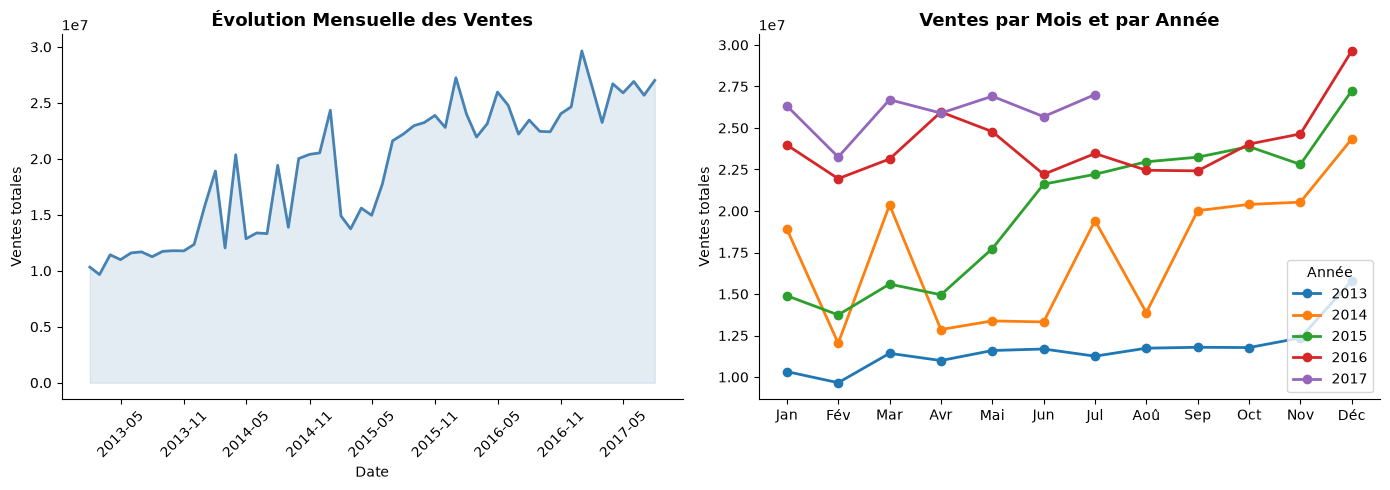

In [40]:
# Agrégation mensuelle pour l'EDA
monthly_eda = train.groupby(pd.Grouper(key='date', freq='ME'))['sales'].sum().reset_index()
monthly_eda.columns = ['date', 'sales']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gauche — évolution mensuelle
axes[0].plot(monthly_eda['date'], monthly_eda['sales'], color='steelblue', linewidth=2)
axes[0].fill_between(monthly_eda['date'], monthly_eda['sales'], alpha=0.15, color='steelblue')
axes[0].set_title('Évolution Mensuelle des Ventes', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Date')
axes[0].set_ylabel('Ventes totales')
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
axes[0].xaxis.set_major_locator(mdates.MonthLocator(interval=6))
plt.setp(axes[0].xaxis.get_majorticklabels(), rotation=45)

# Droite — une courbe par année
month_names = ['Jan','Fév','Mar','Avr','Mai','Jun','Jul','Aoû','Sep','Oct','Nov','Déc']
for i, year in enumerate([2013, 2014, 2015, 2016, 2017]):
    dy = train[train['year'] == year].groupby('month')['sales'].sum()
    axes[1].plot(dy.index, dy.values, marker='o', label=str(year),
                 color=sns.color_palette("tab10", 5)[i], linewidth=2)
axes[1].set_xticks(range(1,13))
axes[1].set_xticklabels(month_names)
axes[1].set_title('Ventes par Mois et par Année', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Ventes totales')
axes[1].legend(title='Année')

plt.tight_layout()
plt.savefig('plot_evolution.png', dpi=150, bbox_inches='tight')
plt.show()


### 3.4 Variables Externes — Pétrole, Promotions & Transactions

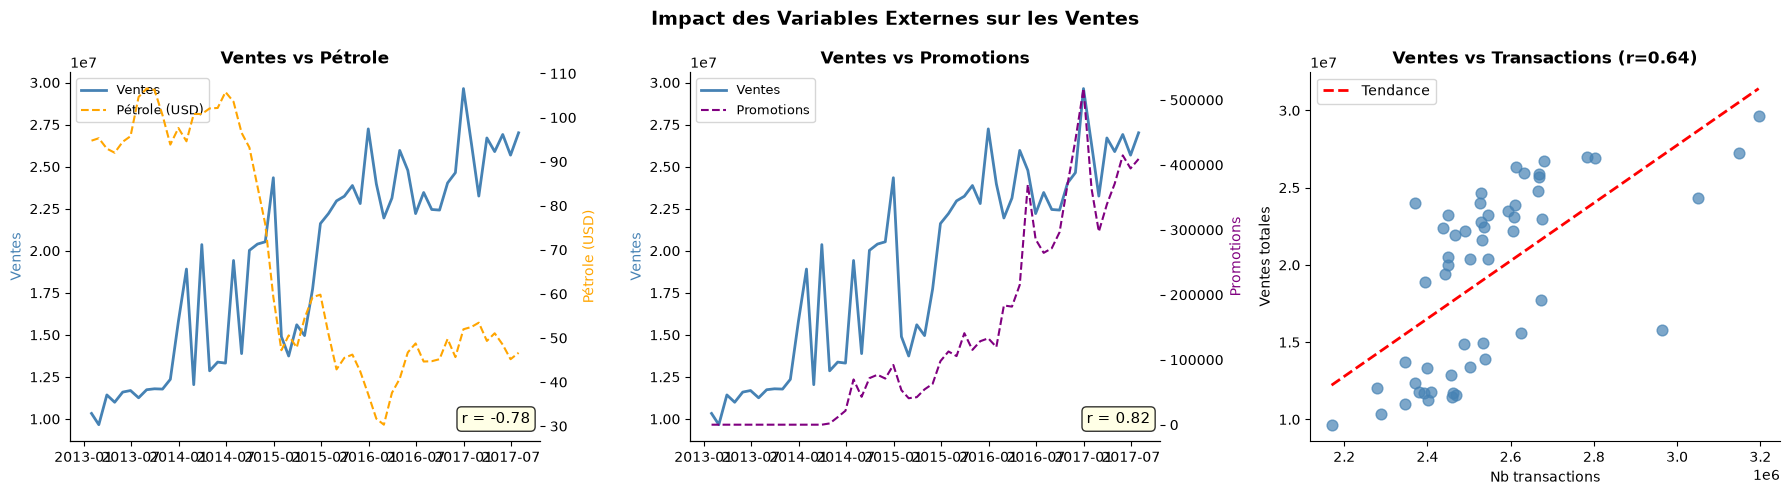

In [41]:
# Préparation des séries mensuelles pour comparaison
oil_m   = oil.set_index('date')['dcoilwtico'].resample('ME').mean().reset_index()
oil_m.columns = ['date', 'oil_price']

promo_m = train.groupby(pd.Grouper(key='date', freq='ME'))['onpromotion'].sum().reset_index()

trans_m = transactions.groupby(pd.Grouper(key='date', freq='ME'))['transactions'].sum().reset_index()
trans_m.columns = ['date', 'n_transactions']

# Fusion sur monthly_eda
ext = monthly_eda.merge(oil_m, on='date', how='left')
ext = ext.merge(promo_m, on='date', how='left')
ext = ext.merge(trans_m, on='date', how='left')

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

def dual_plot(ax, x, y1, y2, label1, label2, color1, color2, title):
    ax2 = ax.twinx()
    ax.plot(x, y1, color=color1, linewidth=2, label=label1)
    ax2.plot(x, y2, color=color2, linewidth=1.5, linestyle='--', label=label2)
    ax.set_ylabel(label1, color=color1)
    ax2.set_ylabel(label2, color=color2)
    ax.set_title(title, fontsize=12, fontweight='bold')
    corr = pd.Series(y1).corr(pd.Series(y2))
    ax.text(0.98, 0.05, f'r = {corr:.2f}', transform=ax.transAxes, ha='right',
            fontsize=11, bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))
    l1, lb1 = ax.get_legend_handles_labels()
    l2, lb2 = ax2.get_legend_handles_labels()
    ax.legend(l1+l2, lb1+lb2, loc='upper left', fontsize=9)

dual_plot(axes[0], ext['date'], ext['sales'], ext['oil_price'],
          'Ventes', 'Pétrole (USD)', 'steelblue', 'orange', 'Ventes vs Pétrole')
dual_plot(axes[1], ext['date'], ext['sales'], ext['onpromotion'],
          'Ventes', 'Promotions', 'steelblue', 'purple', 'Ventes vs Promotions')

# Scatter transactions
axes[2].scatter(ext['n_transactions'], ext['sales'], color='steelblue', alpha=0.7, s=60)
z = np.polyfit(ext['n_transactions'].dropna(), ext['sales'][ext['n_transactions'].notna()], 1)
x_line = np.linspace(ext['n_transactions'].min(), ext['n_transactions'].max(), 100)
axes[2].plot(x_line, np.poly1d(z)(x_line), color='red', linewidth=2, linestyle='--', label='Tendance')
corr3 = ext[['sales','n_transactions']].corr().iloc[0,1]
axes[2].set_title(f'Ventes vs Transactions (r={corr3:.2f})', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Nb transactions')
axes[2].set_ylabel('Ventes totales')
axes[2].legend()

plt.suptitle('Impact des Variables Externes sur les Ventes', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('plot_external.png', dpi=150, bbox_inches='tight')
plt.show()


## 4.  Prétraitement
### 4.1 Création de la Série Temporelle Mensuelle

In [42]:
# ============================================================
# CRÉATION DE MONTHLY — source unique pour tous les modèles
# ============================================================

# Ventes mensuelles
monthly = (train.groupby(pd.Grouper(key='date', freq='ME'))['sales']
           .sum().reset_index()
           .rename(columns={'date': 'ds', 'sales': 'y'}))

# Pétrole
monthly = monthly.merge(oil_m.rename(columns={'date':'ds'}), on='ds', how='left')

# Transactions
monthly = monthly.merge(trans_m.rename(columns={'date':'ds'}), on='ds', how='left')

# Fériés
holidays['ym'] = holidays['date'].dt.to_period('M')
hol_m = holidays.groupby('ym').agg(
    n_events        = ('type', 'count'),
    n_national_hols = ('type', lambda x: (x == 'Holiday').sum()),
    n_transferred   = ('transferred', 'sum')
).reset_index()
monthly['ym'] = monthly['ds'].dt.to_period('M')
monthly = monthly.merge(hol_m, on='ym', how='left').drop(columns='ym')
monthly[['n_events','n_national_hols','n_transferred']] = monthly[['n_events','n_national_hols','n_transferred']].fillna(0)

# Features temporelles et lag
monthly['month']     = monthly['ds'].dt.month
monthly['year']      = monthly['ds'].dt.year
monthly['month_sin'] = np.sin(2 * np.pi * monthly['month'] / 12)
monthly['month_cos'] = np.cos(2 * np.pi * monthly['month'] / 12)
monthly['lag_1']     = monthly['y'].shift(1)
monthly['lag_12']    = monthly['y'].shift(12)
monthly['roll_3']    = monthly['y'].shift(1).rolling(3).mean()

print(f" monthly créé : {monthly.shape}")
print(f"   Colonnes : {monthly.columns.tolist()}")
display(monthly.head(5))


 monthly créé : (55, 14)
   Colonnes : ['ds', 'y', 'oil_price', 'n_transactions', 'n_events', 'n_national_hols', 'n_transferred', 'month', 'year', 'month_sin', 'month_cos', 'lag_1', 'lag_12', 'roll_3']


,ds,y,oil_price,n_transactions,n_events,n_national_hols,n_transferred,month,year,month_sin,month_cos,lag_1,lag_12,roll_3
0,2013-01-31,1.032762e+07,94.756667,2289558,3.0,1.0,0.0,1,2013,0.500000,8.660254e-01,NaN,NaN,NaN
1,2013-02-28,9.658960e+06,95.308947,2169615,2.0,2.0,0.0,2,2013,0.866025,5.000000e-01,1.032762e+07,NaN,NaN
2,2013-03-31,1.142850e+07,92.938500,2458683,1.0,1.0,0.0,3,2013,1.000000,6.123234e-17,9.658960e+06,NaN,NaN
3,2013-04-30,1.099346e+07,92.021364,2344905,5.0,5.0,0.0,4,2013,0.866025,-5.000000e-01,1.142850e+07,NaN,1.047169e+07
4,2013-05-31,1.159770e+07,94.509545,2467465,5.0,3.0,0.0,5,2013,0.500000,-8.660254e-01,1.099346e+07,NaN,1.069364e+07


### 4.2 Test de Stationnarité (ADF & KPSS)

In [43]:
series = monthly['y'].dropna()

# Test ADF
adf = adfuller(series, autolag='AIC')
print("=" * 50)
print("TEST ADF — Augmented Dickey-Fuller")
print("=" * 50)
print(f"  p-value : {adf[1]:.4f}")
print("   STATIONNAIRE" if adf[1] < 0.05 else "    NON-STATIONNAIRE → d=1 nécessaire")

# Test KPSS
kpss_r = kpss(series, regression='c', nlags='auto')
print("\n" + "=" * 50)
print("TEST KPSS")
print("=" * 50)
print(f"  p-value : {kpss_r[1]:.4f}")
print("   STATIONNAIRE" if kpss_r[1] > 0.05 else "    NON-STATIONNAIRE → d=1 nécessaire")


TEST ADF — Augmented Dickey-Fuller
  p-value : 0.5056
    NON-STATIONNAIRE → d=1 nécessaire

TEST KPSS
  p-value : 0.0100
    NON-STATIONNAIRE → d=1 nécessaire


C:\Users\pc\AppData\Local\Temp\ipykernel_16220\3171100437.py:12: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_r = kpss(series, regression='c', nlags='auto')


ADF après d=1 → p-value : 0.0000
 STATIONNAIRE après différenciation !


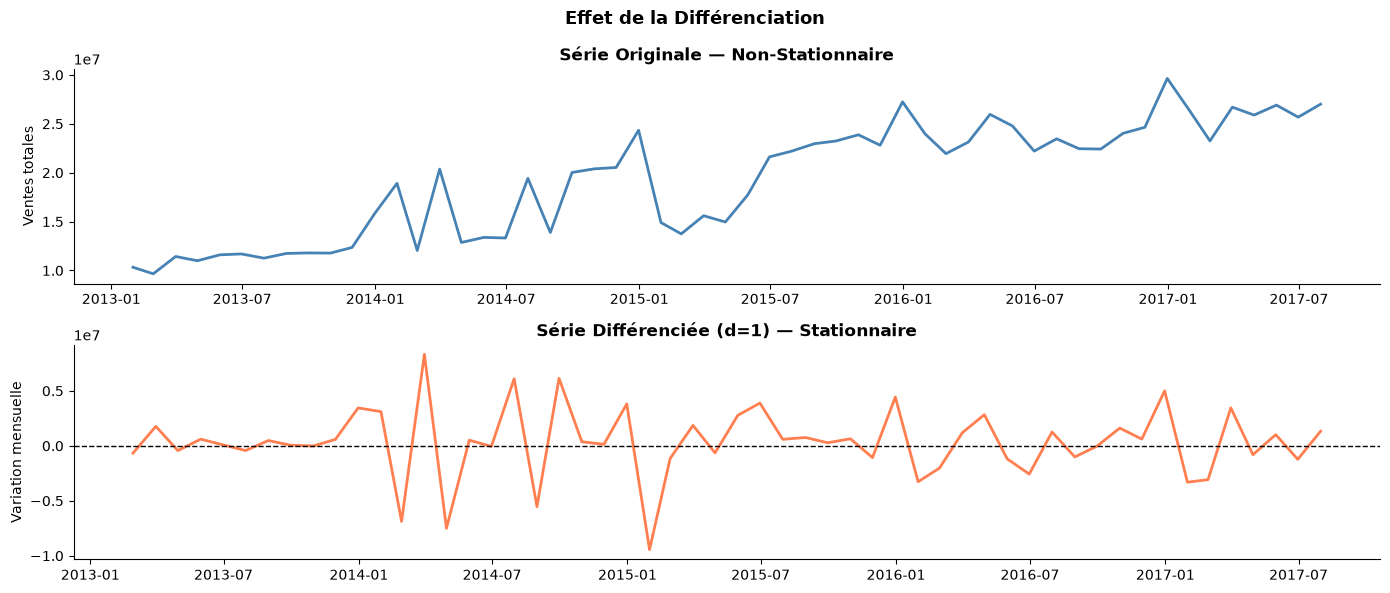

In [44]:
# Différenciation d=1 + re-test
series_diff = series.diff().dropna()
adf_diff = adfuller(series_diff, autolag='AIC')
print(f"ADF après d=1 → p-value : {adf_diff[1]:.4f}")
print(" STATIONNAIRE après différenciation !" if adf_diff[1] < 0.05 else " Toujours non-stationnaire")

# Graphique avant/après
fig, axes = plt.subplots(2, 1, figsize=(14, 6))
axes[0].plot(monthly['ds'], series.values, color='steelblue', linewidth=2)
axes[0].set_title('Série Originale — Non-Stationnaire', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Ventes totales')

axes[1].plot(monthly['ds'].iloc[1:], series_diff.values, color='coral', linewidth=2)
axes[1].axhline(0, color='black', linestyle='--', linewidth=1)
axes[1].set_title('Série Différenciée (d=1) — Stationnaire', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Variation mensuelle')

plt.suptitle('Effet de la Différenciation', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('plot_diff.png', dpi=150, bbox_inches='tight')
plt.show()


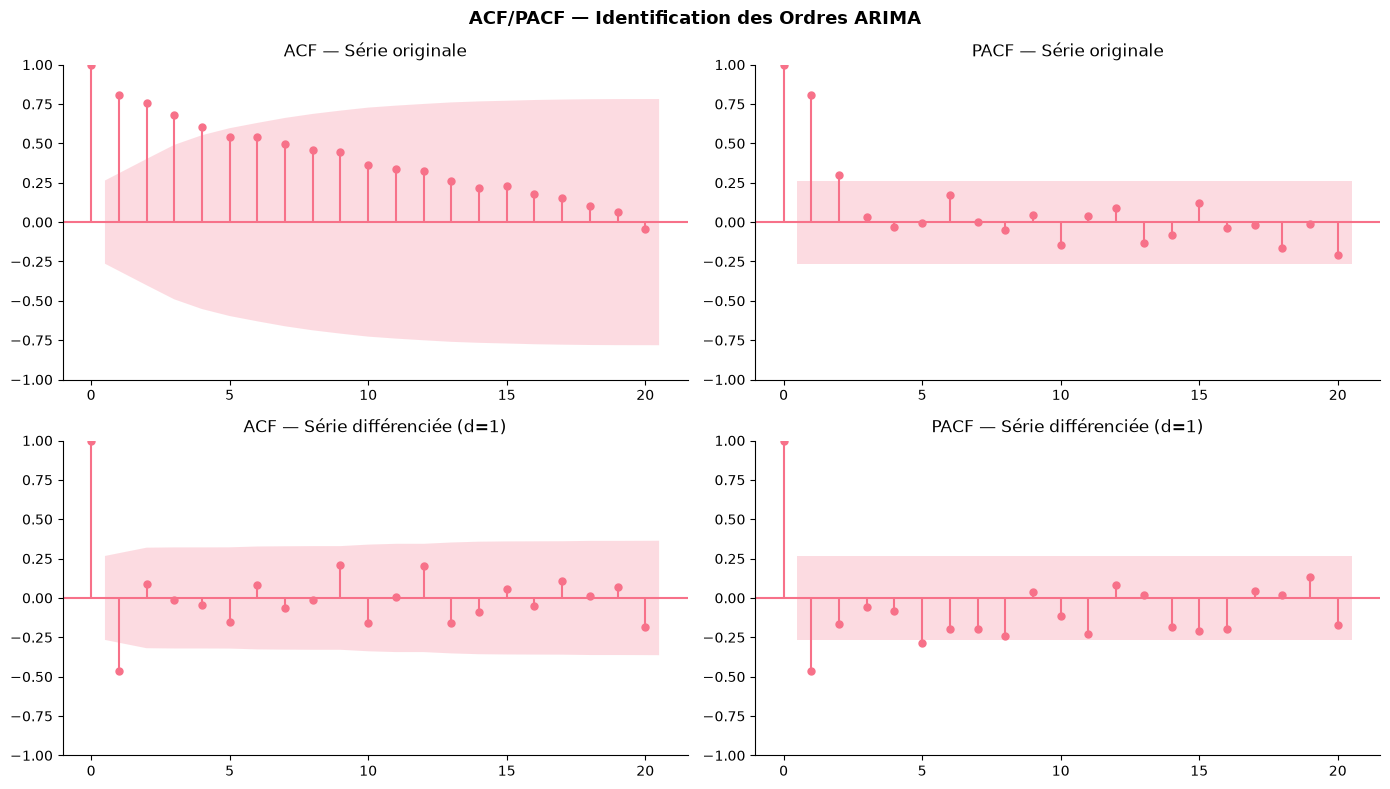

In [45]:
# ACF / PACF — identification des ordres p et q
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
plot_acf( series,      lags=20, ax=axes[0,0], title='ACF — Série originale')
plot_pacf(series,      lags=20, ax=axes[0,1], title='PACF — Série originale')
plot_acf( series_diff, lags=20, ax=axes[1,0], title='ACF — Série différenciée (d=1)')
plot_pacf(series_diff, lags=20, ax=axes[1,1], title='PACF — Série différenciée (d=1)')
plt.suptitle('ACF/PACF — Identification des Ordres ARIMA', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('plot_acf_pacf.png', dpi=150, bbox_inches='tight')
plt.show()


## 5.  Split Train / Validation (80% / 20%)

In [46]:
n         = len(monthly)
split_idx = int(n * 0.80)

df_train = monthly.iloc[:split_idx].copy()
df_val   = monthly.iloc[split_idx:].copy()
y_train  = df_train['y'].values
y_val    = df_val['y'].values

print(f"Train     : {len(df_train)} mois → {df_train['ds'].min().date()} à {df_train['ds'].max().date()}")
print(f"Validation: {len(df_val)} mois → {df_val['ds'].min().date()} à {df_val['ds'].max().date()}")


Train     : 44 mois → 2013-01-31 à 2016-08-31
Validation: 11 mois → 2016-09-30 à 2017-07-31


## 6.  Modèle 1 — ARIMA

In [47]:
# Grid search — trouver le meilleur (p,d,q) selon l'AIC
best_aic, best_order, results = np.inf, None, []

print(" Recherche ARIMA(p,d,q)...")
for p, d, q in product(range(0,4), range(0,2), range(0,4)):
    try:
        res = ARIMA(y_train, order=(p, d, q)).fit()
        results.append({'p':p, 'd':d, 'q':q, 'AIC':res.aic, 'BIC':res.bic})
        if res.aic < best_aic:
            best_aic, best_order = res.aic, (p, d, q)
    except:
        continue

print(f"\n Meilleur : ARIMA{best_order} | AIC = {best_aic:.2f}")
display(pd.DataFrame(results).sort_values('AIC').head(5).reset_index(drop=True))


 Recherche ARIMA(p,d,q)...


c:\Users\pc\Desktop\forecasting-project\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\pc\Desktop\forecasting-project\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\pc\Desktop\forecasting-project\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\pc\Desktop\forecasting-project\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params



 Meilleur : ARIMA(1, 1, 0) | AIC = 1409.83


,p,d,q,AIC,BIC
0,1,1,0,1409.829840,1413.352240
1,0,1,1,1410.411324,1413.933724
2,2,1,0,1411.693231,1416.976832
3,1,1,1,1411.742715,1417.026315
4,0,1,2,1412.249911,1417.533511


In [48]:
# Entraînement avec le meilleur ordre
arima_result = ARIMA(y_train, order=best_order).fit()
print(arima_result.summary())


                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                   44
Model:                 ARIMA(1, 1, 0)   Log Likelihood                -702.915
Date:                Thu, 15 Oct 2026   AIC                           1409.830
Time:                        20:01:54   BIC                           1413.352
Sample:                             0   HQIC                          1411.129
                                 - 44                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.4007      0.093     -4.292      0.000      -0.584      -0.218
sigma2      9.123e+12   1.13e-15   8.07e+27      0.000    9.12e+12    9.12e+12
Ljung-Box (L1) (Q):                   0.75   Jarque-

In [49]:
# Prévisions + métriques
fc          = arima_result.get_forecast(steps=len(y_val))
arima_pred  = fc.predicted_mean
arima_ci    = fc.conf_int()

mae_arima  = mean_absolute_error(y_val, arima_pred)
rmse_arima = np.sqrt(mean_squared_error(y_val, arima_pred))
mape_arima = np.mean(np.abs((y_val - arima_pred) / (y_val + 1e-9))) * 100
r2_arima   = r2_score(y_val, arima_pred)

print(f"MAE  : {mae_arima:>12,.2f}")
print(f"RMSE : {rmse_arima:>12,.2f}")
print(f"MAPE : {mape_arima:>12.2f}%")
print(f"R²   : {r2_arima:>12.4f}")


MAE  : 3,014,167.36
RMSE : 3,519,372.08
MAPE :        11.28%
R²   :      -2.3365


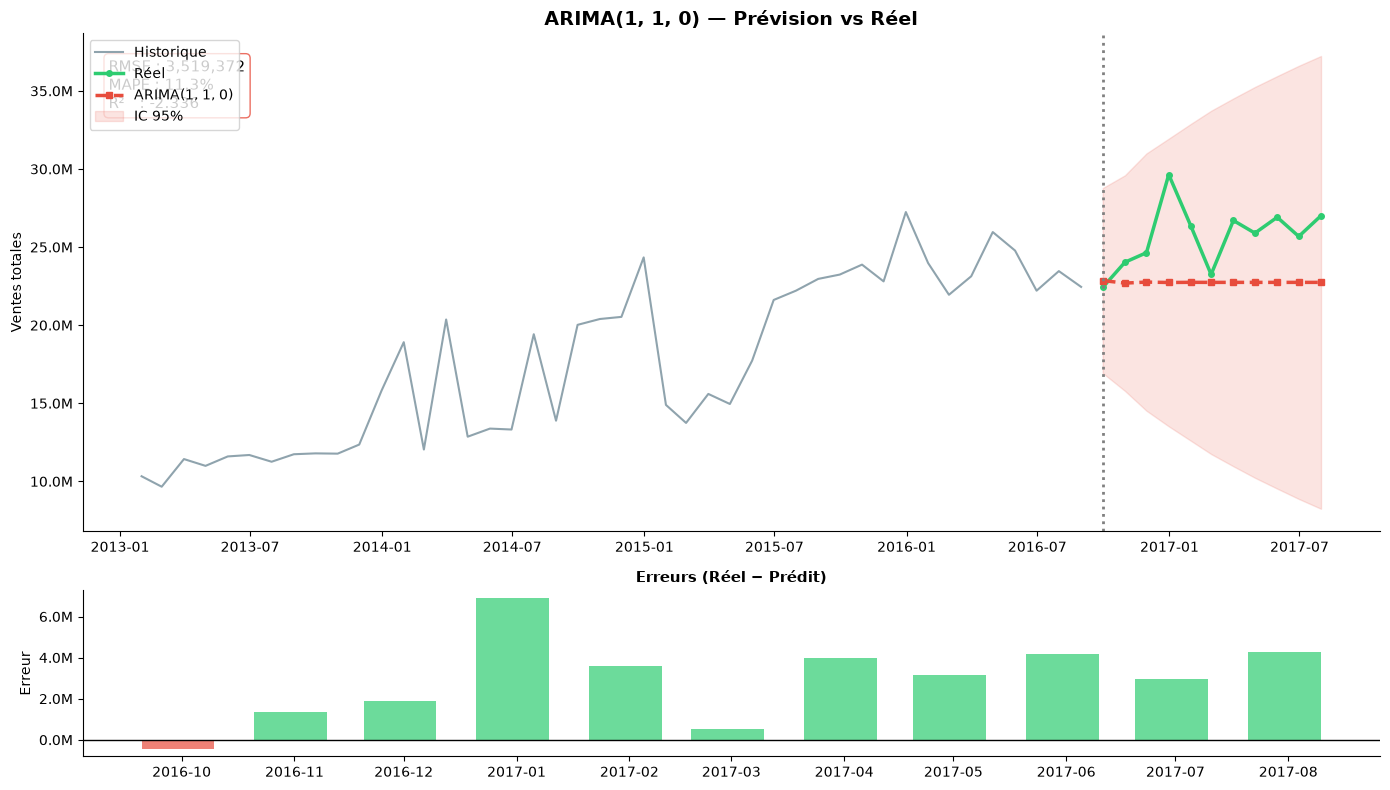

In [50]:
# Graphique ARIMA — prévision + erreurs
fig, axes = plt.subplots(2, 1, figsize=(14, 8), gridspec_kw={'height_ratios': [3, 1]})

axes[0].plot(df_train['ds'], y_train,    label='Historique', color='#607D8B', linewidth=1.5, alpha=0.7)
axes[0].plot(df_val['ds'],   y_val,      label='Réel',       color='#2ecc71', linewidth=2.5, marker='o', markersize=4)
axes[0].plot(df_val['ds'],   arima_pred, label=f'ARIMA{best_order}', color='#e74c3c', linewidth=2.5, linestyle='--', marker='s', markersize=4)
axes[0].fill_between(df_val['ds'], arima_ci[:,0], arima_ci[:,1], alpha=0.15, color='#e74c3c', label='IC 95%')
axes[0].axvline(df_val['ds'].iloc[0], color='gray', linestyle=':', linewidth=2)
axes[0].set_title(f'ARIMA{best_order} — Prévision vs Réel', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Ventes totales')
axes[0].legend(loc='upper left')
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x/1e6:.1f}M'))
axes[0].text(0.02, 0.95, f'RMSE : {rmse_arima:,.0f}\nMAPE : {mape_arima:.1f}%\nR²   : {r2_arima:.3f}',
             transform=axes[0].transAxes, verticalalignment='top', fontsize=11,
             bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='#e74c3c'))

errors = y_val - arima_pred
axes[1].bar(df_val['ds'], errors, color=['#2ecc71' if e>=0 else '#e74c3c' for e in errors], alpha=0.7, width=20)
axes[1].axhline(0, color='black', linewidth=1)
axes[1].set_title('Erreurs (Réel − Prédit)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Erreur')
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x/1e6:.1f}M'))

plt.tight_layout()
plt.savefig('plot_arima.png', dpi=150, bbox_inches='tight')
plt.show()

## 7.  Modèle 2 — Prophet (Meta)

In [51]:
# Prophet — avec pétrole et transactions comme régresseurs
prophet_train = df_train[['ds','y','oil_price','n_transactions']].copy()
prophet_val   = df_val[['ds','y','oil_price','n_transactions']].copy()

prophet_model = Prophet(
    yearly_seasonality      = True,
    weekly_seasonality      = False,
    daily_seasonality       = False,
    seasonality_mode        = 'multiplicative',
    changepoint_prior_scale = 0.1,
    seasonality_prior_scale = 10.0,
    interval_width          = 0.95
)
prophet_model.add_regressor('oil_price')
prophet_model.add_regressor('n_transactions')
prophet_model.fit(prophet_train)
print(" Prophet entraîné avec pétrole + transactions")


20:01:56 - cmdstanpy - INFO - Chain [1] start processing
20:01:56 - cmdstanpy - INFO - Chain [1] done processing


 Prophet entraîné avec pétrole + transactions


In [52]:
# Prévisions + métriques
prophet_fc   = prophet_model.predict(prophet_val[['ds','oil_price','n_transactions']])
y_pred_proph = prophet_fc['yhat'].values

mae_proph  = mean_absolute_error(y_val, y_pred_proph)
rmse_proph = np.sqrt(mean_squared_error(y_val, y_pred_proph))
mape_proph = np.mean(np.abs((y_val - y_pred_proph) / (y_val + 1e-9))) * 100
r2_proph   = r2_score(y_val, y_pred_proph)

print(f"MAE  : {mae_proph:>12,.2f}")
print(f"RMSE : {rmse_proph:>12,.2f}")
print(f"MAPE : {mape_proph:>12.2f}%")
print(f"R²   : {r2_proph:>12.4f}")


MAE  : 3,732,173.77
RMSE : 3,962,815.13
MAPE :        14.68%
R²   :      -3.2303


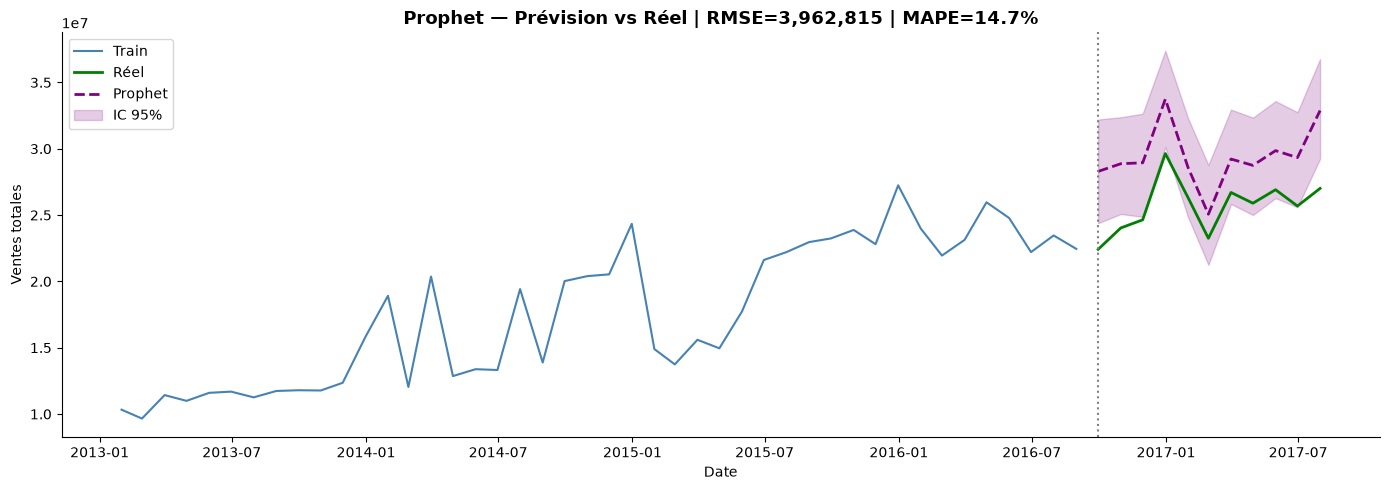

In [53]:
# Graphique Prophet
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df_train['ds'], y_train,           label='Train',       color='steelblue', linewidth=1.5)
ax.plot(df_val['ds'],   y_val,             label='Réel',        color='green',     linewidth=2)
ax.plot(prophet_fc['ds'], prophet_fc['yhat'], label='Prophet',  color='purple',    linewidth=2, linestyle='--')
ax.fill_between(prophet_fc['ds'], prophet_fc['yhat_lower'], prophet_fc['yhat_upper'],
                alpha=0.2, color='purple', label='IC 95%')
ax.axvline(df_val['ds'].iloc[0], color='gray', linestyle=':', linewidth=1.5)
ax.set_title(f'Prophet — Prévision vs Réel | RMSE={rmse_proph:,.0f} | MAPE={mape_proph:.1f}%', fontsize=13, fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Ventes totales')
ax.legend()
plt.tight_layout()
plt.savefig('plot_prophet.png', dpi=150, bbox_inches='tight')
plt.show()


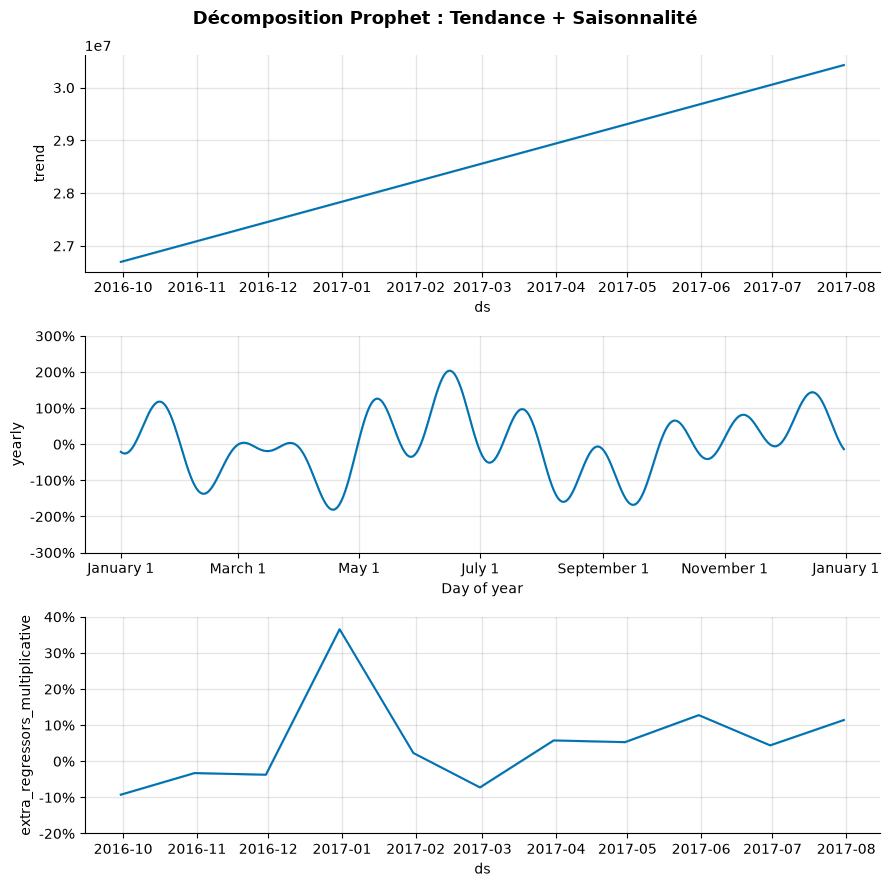

In [54]:
# Décomposition Prophet — tendance et saisonnalité
fig_c = prophet_model.plot_components(prophet_fc)
fig_c.suptitle('Décomposition Prophet : Tendance + Saisonnalité', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('plot_prophet_components.png', dpi=150, bbox_inches='tight')
plt.show()


## 8.  Modèle 3 — LSTR (Logistic Smooth Transition Regression)

Le modèle bascule progressivement entre **deux régimes linéaires** selon une fonction logistique.

In [55]:
# Classe LSTR
class LSTRModel:
    def __init__(self):
        self.params_ = None

    def _G(self, t, gamma, c):
        # Fonction de transition logistique
        return expit(gamma * (t - c))

    def _predict(self, X, t, params):
        n = X.shape[1]
        G = self._G(t, params[-2], params[-1])
        return X @ params[:n] * (1-G) + X @ params[n:2*n] * G

    def _loss(self, params, X, t, y):
        return np.mean((y - self._predict(X, t, params))**2)

    def fit(self, X, t, y):
        from numpy.linalg import lstsq
        n = X.shape[1]
        phi, *_ = lstsq(X, y, rcond=None)
        x0 = np.concatenate([phi, phi, [1.0, np.median(t)]])
        res = minimize(self._loss, x0, args=(X, t, y),
                       method='L-BFGS-B', options={'maxiter': 5000, 'ftol': 1e-12})
        self.params_  = res.x
        self.success_ = res.success
        return self

    def predict(self, X, t):
        return self._predict(X, t, self.params_)

print(" Classe LSTR définie")


 Classe LSTR définie


In [56]:
# Préparation des features pour LSTR
# Stats calculées sur le TRAIN uniquement (pas de data leakage)
oil_mean   = df_train['oil_price'].ffill().bfill().mean()
oil_std    = df_train['oil_price'].ffill().bfill().std()
trans_mean = df_train['n_transactions'].ffill().bfill().mean()
trans_std  = df_train['n_transactions'].ffill().bfill().std()

def make_features(df):
    t = np.arange(len(df), dtype=float)
    t = (t - t.mean()) / t.std()

    oil   = (df['oil_price'].ffill().bfill().values      - oil_mean) / oil_std
    trans = (df['n_transactions'].ffill().bfill().values - trans_mean) / trans_std

    X = np.column_stack([
        np.ones(len(df)),
        t,
        df['month_sin'].values,
        df['month_cos'].values,
        oil,
        trans,
    ])
    return X, t

X_tr, t_tr = make_features(df_train)
X_va, t_va = make_features(df_val)

# Normalisation de y
y_mean = y_train.mean()
y_std  = y_train.std()
y_norm = (y_train - y_mean) / y_std

# Entraînement
lstr = LSTRModel()
lstr.fit(X_tr, t_tr, y_norm)
print(f"Convergence : {lstr.success_}")

# Paramètres
n = X_tr.shape[1]
names = ['Constante','Tendance','sin(mois)','cos(mois)','Pétrole','Transactions']
print("\n=== PARAMÈTRES LSTR ===")
for label, params in [("Régime 1 (φ1)", lstr.params_[:n]), ("Régime 2 (φ2)", lstr.params_[n:2*n])]:
    print(f"\n{label}:")
    for nm, v in zip(names, params):
        print(f"  {nm:15s}: {v*y_std:.2f}")
print(f"\n  gamma (vitesse) : {lstr.params_[-2]:.4f}")
print(f"  c     (pivot)   : {lstr.params_[-1]:.4f}")

Convergence : True

=== PARAMÈTRES LSTR ===

Régime 1 (φ1):
  Constante      : 3324008.60
  Tendance       : 6299652.67
  sin(mois)      : 1355805.88
  cos(mois)      : -58930.00
  Pétrole        : -854376.49
  Transactions   : 864057.61

Régime 2 (φ2):
  Constante      : -468769.54
  Tendance       : 5774797.30
  sin(mois)      : -1539587.04
  cos(mois)      : 1471705.49
  Pétrole        : 1264395.44
  Transactions   : 1498828.75

  gamma (vitesse) : 349.7798
  c     (pivot)   : -0.5485


In [57]:
# Prévisions + métriques
y_pred_lstr = lstr.predict(X_va, t_va) * y_std + y_mean

mae_lstr  = mean_absolute_error(y_val, y_pred_lstr)
rmse_lstr = np.sqrt(mean_squared_error(y_val, y_pred_lstr))
mape_lstr = np.mean(np.abs((y_val - y_pred_lstr) / (y_val + 1e-9))) * 100
r2_lstr   = r2_score(y_val, y_pred_lstr)

print(f"MAE  : {mae_lstr:>12,.2f}")
print(f"RMSE : {rmse_lstr:>12,.2f}")
print(f"MAPE : {mape_lstr:>12.2f}%")
print(f"R²   : {r2_lstr:>12.4f}")


MAE  : 7,675,187.31
RMSE : 8,447,209.67
MAPE :        30.50%
R²   :     -18.2214


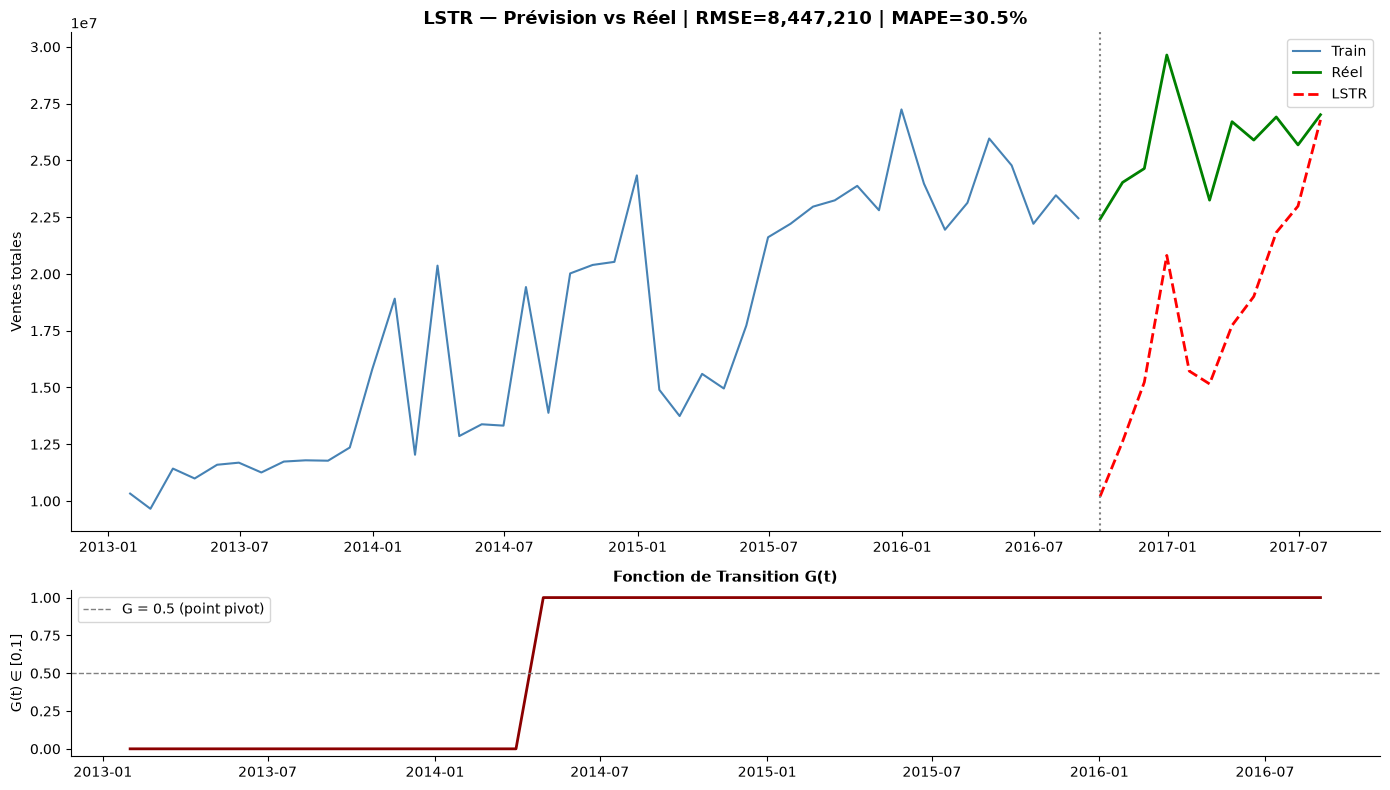

In [58]:
# Graphique LSTR — prévision + fonction de transition
fig, axes = plt.subplots(2, 1, figsize=(14, 8), gridspec_kw={'height_ratios': [3, 1]})

axes[0].plot(df_train['ds'], y_train,      label='Train',        color='steelblue', linewidth=1.5)
axes[0].plot(df_val['ds'],   y_val,        label='Réel',         color='green',     linewidth=2)
axes[0].plot(df_val['ds'],   y_pred_lstr,  label='LSTR',         color='red',       linewidth=2, linestyle='--')
axes[0].axvline(df_val['ds'].iloc[0], color='gray', linestyle=':', linewidth=1.5)
axes[0].set_title(f'LSTR — Prévision vs Réel | RMSE={rmse_lstr:,.0f} | MAPE={mape_lstr:.1f}%', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Ventes totales')
axes[0].legend()

# Fonction de transition G(t)
G = 1 / (1 + np.exp(-lstr.params_[-2] * (t_tr - lstr.params_[-1])))
axes[1].plot(df_train['ds'], G, color='darkred', linewidth=2)
axes[1].axhline(0.5, color='gray', linestyle='--', linewidth=1, label='G = 0.5 (point pivot)')
axes[1].set_title('Fonction de Transition G(t)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('G(t) ∈ [0,1]')
axes[1].legend()

plt.tight_layout()
plt.savefig('plot_lstr.png', dpi=150, bbox_inches='tight')
plt.show()


## 9. Comparaison des Modèles

In [59]:
# Tableau comparatif
metrics = pd.DataFrame({
    'Modèle':   ['ARIMA', 'Prophet', 'LSTR'],
    'MAE':      [mae_arima,  mae_proph,  mae_lstr],
    'RMSE':     [rmse_arima, rmse_proph, rmse_lstr],
    'MAPE (%)': [mape_arima, mape_proph, mape_lstr],
    'R²':       [r2_arima,   r2_proph,   r2_lstr],
}).sort_values('RMSE').reset_index(drop=True)

display(metrics.style.format({'MAE':'{:,.0f}','RMSE':'{:,.0f}','MAPE (%)':'{:.2f}%','R²':'{:.4f}'}))
print(f"\n Meilleur modèle : {metrics.iloc[0]['Modèle']}")


,Modèle,MAE,RMSE,MAPE (%),R²
0,ARIMA,"3,014,167","3,519,372",11.28%,-2.3365
1,Prophet,"3,732,174","3,962,815",14.68%,-3.2303
2,LSTR,"7,675,187","8,447,210",30.50%,-18.2214



 Meilleur modèle : ARIMA


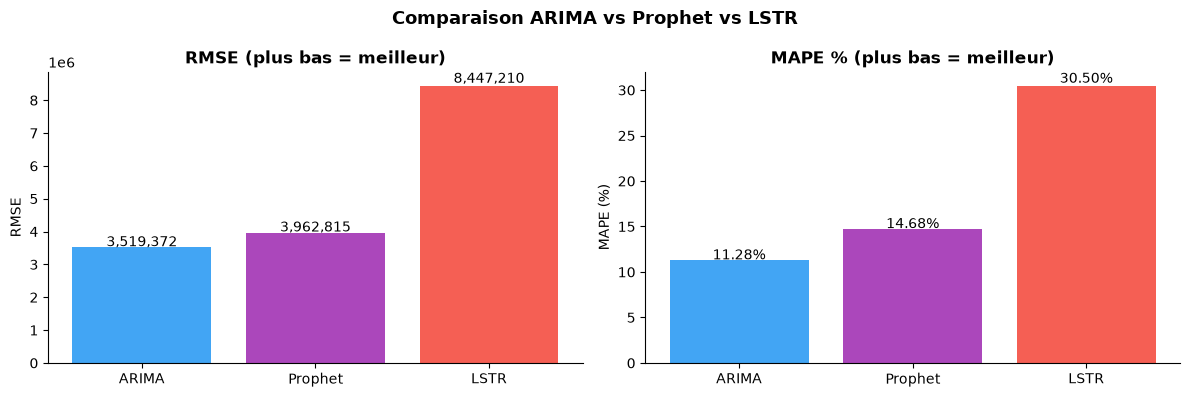

In [60]:
# Graphiques comparatifs
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
colors = ['#2196F3', '#9C27B0', '#F44336']

axes[0].bar(metrics['Modèle'], metrics['RMSE'], color=colors, alpha=0.85)
axes[0].set_title('RMSE (plus bas = meilleur)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('RMSE')
for i, row in metrics.iterrows():
    axes[0].text(i, row['RMSE']*1.01, f"{row['RMSE']:,.0f}", ha='center', fontsize=10)

axes[1].bar(metrics['Modèle'], metrics['MAPE (%)'], color=colors, alpha=0.85)
axes[1].set_title('MAPE % (plus bas = meilleur)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('MAPE (%)')
for i, row in metrics.iterrows():
    axes[1].text(i, row['MAPE (%)']*1.01, f"{row['MAPE (%)']:.2f}%", ha='center', fontsize=10)

plt.suptitle('Comparaison ARIMA vs Prophet vs LSTR', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('plot_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


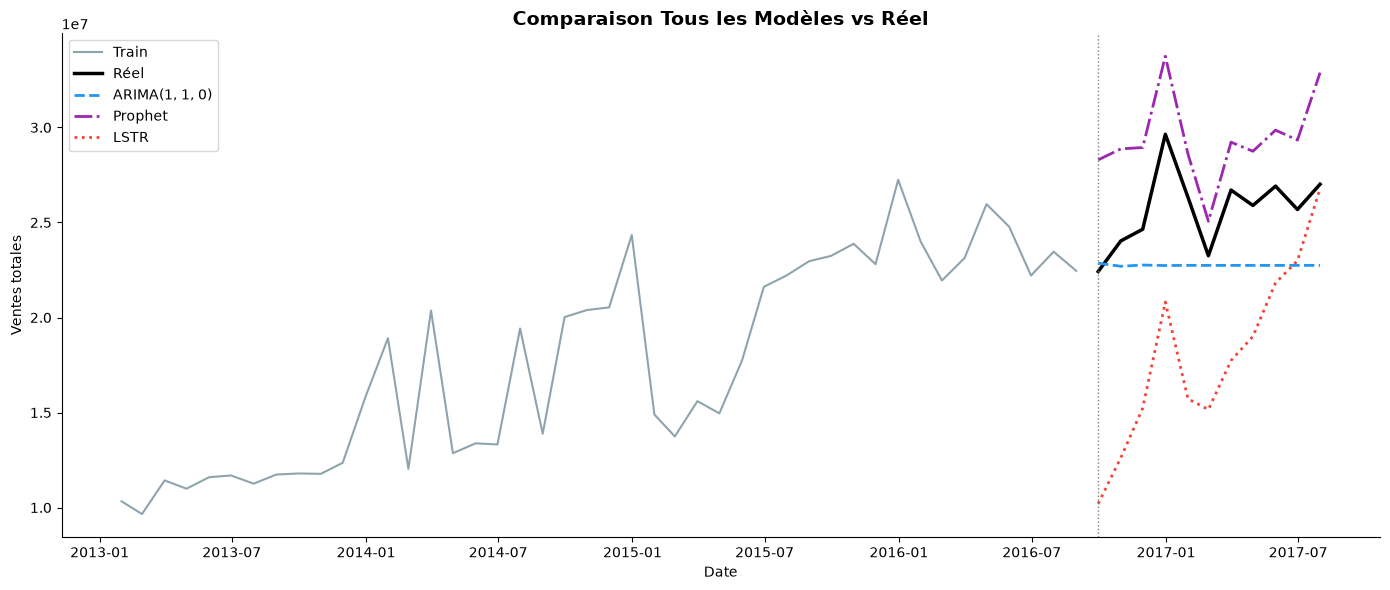

In [61]:
# Tous les modèles superposés
fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(df_train['ds'], y_train,      label='Train',           color='#607D8B', linewidth=1.5, alpha=0.7)
ax.plot(df_val['ds'],   y_val,        label='Réel',            color='black',   linewidth=2.5)
ax.plot(df_val['ds'],   arima_pred,   label=f'ARIMA{best_order}', color='#2196F3', linewidth=2, linestyle='--')
ax.plot(df_val['ds'],   y_pred_proph, label='Prophet',         color='#9C27B0', linewidth=2, linestyle='-.')
ax.plot(df_val['ds'],   y_pred_lstr,  label='LSTR',            color='#F44336', linewidth=2, linestyle=':')
ax.axvline(df_val['ds'].iloc[0], color='gray', linestyle=':', linewidth=1)
ax.set_title('Comparaison Tous les Modèles vs Réel', fontsize=14, fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Ventes totales')
ax.legend(loc='upper left')
plt.tight_layout()
plt.savefig('plot_all_models.png', dpi=150, bbox_inches='tight')
plt.show()


## 10.  Prévisions Finales — 6 Prochains Mois

In [62]:
# Réentraîner Prophet sur toutes les données
full = monthly[['ds','y','oil_price','n_transactions']].copy()
oil_last   = full['oil_price'].dropna().iloc[-1]
trans_last = full['n_transactions'].dropna().iloc[-1]

prophet_final = Prophet(
    yearly_seasonality      = True,
    weekly_seasonality      = False,
    daily_seasonality       = False,
    seasonality_mode        = 'multiplicative',
    changepoint_prior_scale = 0.1,
    interval_width          = 0.95
)
prophet_final.add_regressor('oil_price')
prophet_final.add_regressor('n_transactions')
prophet_final.fit(full)

# Dates futures
future = pd.DataFrame({
    'ds'            : pd.date_range(start=full['ds'].max() + pd.DateOffset(months=1), periods=6, freq='ME'),
    'oil_price'     : oil_last,
    'n_transactions': trans_last
})
fc_final = prophet_final.predict(future)

# Tableau résultat
res = fc_final[['ds','yhat','yhat_lower','yhat_upper']].copy()
res.columns = ['Date','Prévision','IC_bas','IC_haut']
res['Date'] = res['Date'].dt.strftime('%Y-%m')
res[['Prévision','IC_bas','IC_haut']] = res[['Prévision','IC_bas','IC_haut']].round(0).astype(int)
display(res)


20:02:01 - cmdstanpy - INFO - Chain [1] start processing
20:02:01 - cmdstanpy - INFO - Chain [1] done processing


,Date,Prévision,IC_bas,IC_haut
0,2017-08,28264410,24726046,31789291
1,2017-09,31362431,27854088,34719026
2,2017-10,31454252,27667894,34875128
3,2017-11,31931612,28072518,35230430
4,2017-12,28146236,24386291,31956323
5,2018-01,32329548,28647421,36431433


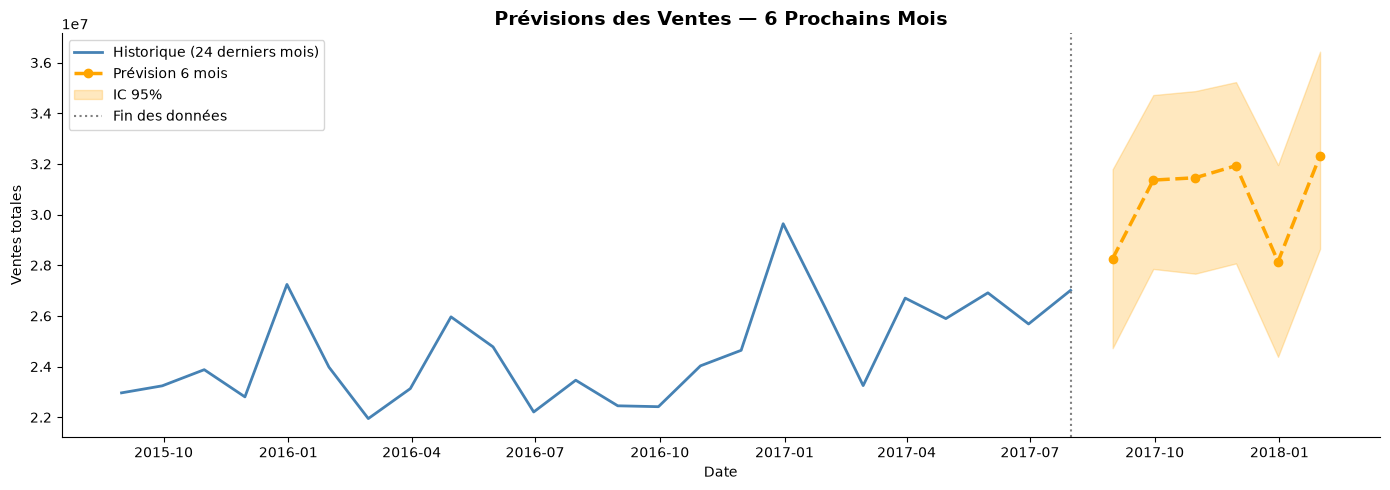

In [63]:
# Graphique prévisions finales
fig, ax = plt.subplots(figsize=(14, 5))
recent = full.tail(24)
ax.plot(recent['ds'], recent['y'], label='Historique (24 derniers mois)', color='steelblue', linewidth=2)
ax.plot(fc_final['ds'], fc_final['yhat'], label='Prévision 6 mois', color='orange', linewidth=2.5, linestyle='--', marker='o')
ax.fill_between(fc_final['ds'], fc_final['yhat_lower'], fc_final['yhat_upper'],
                alpha=0.25, color='orange', label='IC 95%')
ax.axvline(full['ds'].max(), color='gray', linestyle=':', linewidth=1.5, label='Fin des données')
ax.set_title('Prévisions des Ventes — 6 Prochains Mois', fontsize=14, fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Ventes totales')
ax.legend()
plt.tight_layout()
plt.savefig('plot_forecast_final.png', dpi=150, bbox_inches='tight')
plt.show()


## 11.  Résumé & Conclusions

| Modèle | Forces | Faiblesses |
|--------|--------|------------|
| **ARIMA** | Simple, interprétable, aucun régresseur nécessaire | Linéaire, prédit une valeur quasi-constante |
| **Prophet** | Saisonnalité + régresseurs externes + IC natifs | Moins interprétable |
| **LSTR** | Capture le changement de régime 2015 | Nécessite beaucoup de données pour calibrer γ et c |

**Pistes d'amélioration :** Modèles hiérarchiques par famille/magasin · XGBoost · SARIMA(p,d,q)(P,D,Q,12)

In [66]:
print("=" * 60)
print("    RÉSUMÉ — PRÉVISION DES VENTES MENSUELLES")
print("=" * 60)
print(f"  Dataset     : 2,974,158 obs | 54 magasins | 33 familles")
print(f"  Période     : 2013-01-01 → 2017-07-31")
print(f"  Split       : 80% train / 20% validation")
print(f"  Régresseurs : Prix pétrole + Transactions")
print()
print(f"  ARIMA{best_order}       : RMSE={rmse_arima:>12,.0f} | MAPE={mape_arima:.2f}%")
print(f"  Prophet      : RMSE={rmse_proph:>12,.0f} | MAPE={mape_proph:.2f}%")
print(f"  LSTR         : RMSE={rmse_lstr:>12,.0f} | MAPE={mape_lstr:.2f}%")
print()
print(f"   Meilleur modèle : {metrics.iloc[0]['Modèle']}")
print("=" * 60)


    RÉSUMÉ — PRÉVISION DES VENTES MENSUELLES
  Dataset     : 2,974,158 obs | 54 magasins | 33 familles
  Période     : 2013-01-01 → 2017-07-31
  Split       : 80% train / 20% validation
  Régresseurs : Prix pétrole + Transactions

  ARIMA(1, 1, 0)       : RMSE=   3,519,372 | MAPE=11.28%
  Prophet      : RMSE=   3,962,815 | MAPE=14.68%
  LSTR         : RMSE=   8,447,210 | MAPE=30.50%

   Meilleur modèle : ARIMA
